In [131]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, LeaveOneGroupOut, ParameterGrid
import homoglyphs as hg
import re
import string
import unicodedata
from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import classification_report, accuracy_score, balanced_accuracy_score, f1_score, confusion_matrix
from sklearn.linear_model import LogisticRegression
import copy
import shap
import matplotlib.pyplot as plt

In [20]:
LING_SPAM_PATH = './datasets/Ling-Spam.csv'
NAZARIO_PATH = './datasets/Nazario.csv'
NIGERIAN_FRAUD_PATH = './datasets/Nigerian_Fraud.csv'
SPAMASSASSIN_PATH = './datasets/SpamAssasin.csv'

REQUIRED_COLUMNS = ['body', 'label']

DATASETS = {
    "Ling-Spam": LING_SPAM_PATH,
    "Nazario": NAZARIO_PATH,  # not using Nazario_5
    "Nigerian_Fraud": NIGERIAN_FRAUD_PATH,
    "SpamAssasin": SPAMASSASSIN_PATH
}

# Set random seed for reproducibility
np.random.seed(42)

# Load the dataset individually
#df = pd.read_csv(DATASETS["Ling-Spam"])

#df.head()

# Data Exploration and Preprocessing

In [21]:
# Check for missing values in each dataset and the different datatypes of the columns
for index, name in DATASETS.items():
    print(f"Dataset: {name}")
    df = pd.read_csv(DATASETS[index])
    print(f"{df.isnull().sum()} + \n")
    print(f"{df.info()}" + "\n")

    # Body and label columns are the only common columns across all datasets, so we will only keep those columns for further analysis

Dataset: ./datasets/Ling-Spam.csv
subject    62
message     0
label       0
dtype: int64 + 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2893 entries, 0 to 2892
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   subject  2831 non-null   object
 1   message  2893 non-null   object
 2   label    2893 non-null   int64 
dtypes: int64(1), object(2)
memory usage: 67.9+ KB
None

Dataset: ./datasets/Nazario.csv
sender       0
receiver    96
date         1
subject      4
body         0
urls         0
label        0
dtype: int64 + 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1565 entries, 0 to 1564
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   sender    1565 non-null   object
 1   receiver  1469 non-null   object
 2   date      1564 non-null   object
 3   subject   1561 non-null   object
 4   body      1565 non-null   object
 5   urls      1565 non-null   in

In [22]:
# Check the distribution of labels in each dataset
for index, name in DATASETS.items():
    print(f"Dataset: {name}")
    df = pd.read_csv(DATASETS[index])
    print(f"{df['label'].value_counts(dropna=False)}" + "\n")

Dataset: ./datasets/Ling-Spam.csv
label
0    2412
1     481
Name: count, dtype: int64

Dataset: ./datasets/Nazario.csv
label
1    1565
Name: count, dtype: int64

Dataset: ./datasets/Nigerian_Fraud.csv
label
1    3332
Name: count, dtype: int64

Dataset: ./datasets/SpamAssasin.csv
label
0    4091
1    1718
Name: count, dtype: int64



In [23]:
# Cleaning the SpamAssassin dataset
def clean_spam_assassin(spam_assassin_df):
    if 'body' in spam_assassin_df.columns:
        spam_assassin_df['body'] = spam_assassin_df['body'].fillna('')
    return spam_assassin_df


# Cleaning the Ling-Spam dataset
def clean_ling_spam(ling_spam_df):
    if 'message' in ling_spam_df.columns:
        ling_spam_df = ling_spam_df.rename(columns={'message': 'body'})
    return ling_spam_df



In [24]:
raw_datasets = {}
cleaned_datasets = {}


def preprocess_datasets():
    for name, path in DATASETS.items():
        df = pd.read_csv(path)
        raw_datasets[name] = df

    for name, df in raw_datasets.items():
        df = clean_spam_assassin(df) if name == "SpamAssasin" else df
        df = clean_ling_spam(df) if name == "Ling-Spam" else df

        for column in REQUIRED_COLUMNS:
            if column not in df.columns:
                raise ValueError(f"Column '{column}' is missing in dataset '{name}'")

            cleaned_datasets[name] = df[REQUIRED_COLUMNS].copy()

    for name, df in cleaned_datasets.items():
        print(f"Dataset: {name}")
        print(f"{df.info()}" + "\n")


preprocess_datasets()


Dataset: Ling-Spam
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2893 entries, 0 to 2892
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   body    2893 non-null   object
 1   label   2893 non-null   int64 
dtypes: int64(1), object(1)
memory usage: 45.3+ KB
None

Dataset: Nazario
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1565 entries, 0 to 1564
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   body    1565 non-null   object
 1   label   1565 non-null   int64 
dtypes: int64(1), object(1)
memory usage: 24.6+ KB
None

Dataset: Nigerian_Fraud
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3332 entries, 0 to 3331
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   body    3332 non-null   object
 1   label   3332 non-null   int64 
dtypes: int64(1), object(1)
memory usage: 52.2+ KB
None

Dataset: SpamAssasi

In [25]:
# PS: Some overlapping body content between the training and testing datasets may exist, which may lead to data leakage and overestimation of the model's performance.
def normalize_body(text):
    return re.sub(r'\s+', ' ', str(text)).lower().strip()


# Only used for metadata/leakage detection not for the training of the model
def remove_duplicates_in_dataset(df, dataset_name):
    result = df.copy()

    result["normalized_body"] = result["body"].map(normalize_body)

    # Remove empty bodies
    result = result[result["normalized_body"] != ""].copy()

    # Check duplicate bodies with different labels before removing duplicates.
    conflicting_bodies = result.groupby("normalized_body")["label"].nunique()

    print(f"Number of conflicting bodies in {dataset_name}: {conflicting_bodies[conflicting_bodies > 1].shape[0]}")

    # Keep copy of each normalized body
    result = result.drop_duplicates(subset="normalized_body", keep="first").reset_index(
        drop=True)  # within this dataset

    return result


deduplicated_datasets = {}

for name, df in cleaned_datasets.items():
    deduplicated_datasets[name] = remove_duplicates_in_dataset(df, name)

    dedup_df = deduplicated_datasets[name]
    print(f"Dataset: {name}")
    print(f"Label counts: {dedup_df['label'].value_counts()}")
    print(f"Shape: {dedup_df.shape}")

Number of conflicting bodies in Ling-Spam: 0
Dataset: Ling-Spam
Label counts: label
0    2401
1     458
Name: count, dtype: int64
Shape: (2859, 3)
Number of conflicting bodies in Nazario: 0
Dataset: Nazario
Label counts: label
1    1526
Name: count, dtype: int64
Shape: (1526, 3)
Number of conflicting bodies in Nigerian_Fraud: 0
Dataset: Nigerian_Fraud
Label counts: label
1    3270
Name: count, dtype: int64
Shape: (3270, 3)
Number of conflicting bodies in SpamAssasin: 0
Dataset: SpamAssasin
Label counts: label
0    4090
1    1694
Name: count, dtype: int64
Shape: (5784, 3)


In [26]:
# Using a pipeline with TfidfVectorizer and XGBClassifier for the baseline model.

# 4-fold structure partitioning the benign side of Ling-Spam and SpamAssassin to be used for training data on test phishing datasets.

ling_dataset = deduplicated_datasets["Ling-Spam"].copy()
spam_assassin = deduplicated_datasets["SpamAssasin"].copy()
nigerian_fraud = deduplicated_datasets["Nigerian_Fraud"].copy()
nazario = deduplicated_datasets["Nazario"].copy()

ling_benign = ling_dataset[ling_dataset['label'] == 0].copy()
ling_spam = ling_dataset[ling_dataset['label'] == 1].copy()

spam_assassin_benign = spam_assassin[spam_assassin['label'] == 0].copy()
spam_assassin_spam = spam_assassin[spam_assassin['label'] == 1].copy()

# 80 20 train-test split for the benign side of spam datasets
ling_benign_train, ling_benign_test = train_test_split(ling_benign, test_size=0.2, random_state=42)
spam_assassin_benign_train, spam_assassin_benign_test = train_test_split(spam_assassin_benign, test_size=0.2,
                                                                         random_state=42)

ling_benign_train = ling_benign_train.assign(source="Ling-Spam")
ling_benign_test = ling_benign_test.assign(source="Ling-Spam")
ling_spam = ling_spam.assign(source="Ling-Spam")
spam_assassin_benign_train = spam_assassin_benign_train.assign(source="SpamAssassin")
spam_assassin_benign_test = spam_assassin_benign_test.assign(source="SpamAssassin")
spam_assassin_spam = spam_assassin_spam.assign(source="SpamAssassin")

nazario = nazario.assign(source="Nazario")
nigerian_fraud = nigerian_fraud.assign(source="Nigerian_Fraud")

# combined benign training and testing datasets
benign_train = pd.concat(
    [
        ling_benign_train,
        spam_assassin_benign_train
    ],
    ignore_index=True
)

benign_test = pd.concat(
    [
        ling_benign_test,
        spam_assassin_benign_test
    ],
    ignore_index=True
)

# Build custom four-fold LODO evaluation structure for cross-dataset evaluation design
folds = {
    "Ling-Spam": {
        "train": pd.concat(
            [
                spam_assassin_benign_train,
                nigerian_fraud,
                nazario
            ],
            ignore_index=True,
        ),
        "test": ling_dataset,
    },
    "SpamAssassin": {
        "train": pd.concat(
            [
                ling_benign_train,
                nigerian_fraud,
                nazario
            ],
            ignore_index=True,
        ),
        "test": spam_assassin
    },
    "Nigerian_Fraud": {
        "train": pd.concat(
            [
                benign_train,
                nazario
            ],
            ignore_index=True
        ),

        "test": pd.concat([
            benign_test,
            nigerian_fraud
        ],
            ignore_index=True)
    },
    "Nazario": {
        "train": pd.concat(
            [
                benign_train,
                nigerian_fraud
            ], ignore_index=True

        ),
        "test": pd.concat(
            [
                benign_test,
                nazario
            ],
            ignore_index=True
        ),
    }
}

folds["Ling-Spam"]["test"] = folds["Ling-Spam"]["test"].assign(source="Ling-Spam")
folds["SpamAssassin"]["test"] = folds["SpamAssassin"]["test"].assign(source="SpamAssassin")

# TF-IDF + XGBoost Classifier (XGB) Baseline

In [27]:
# Training datasets for cross-dataset evaluation design using leave-one-dataset-out evaluation strategy. The training datasets are created by combining three datasets and the testing dataset is the remaining one.

# TF-IDF vectorization parameters
#analyzer = ['word', 'char_wb']
#ngram_range = [(1, 2), (3, 5)] # word-level and char-level
#max_features= [50000, 200000] # word-level and char-level
TFIDF_PARAMS = {
    "analyzer": "word",
    "ngram_range": (1, 2),
    "min_df": 2,
    "max_df": 0.5,
    "sublinear_tf": True,
    "dtype": np.float32,
    "max_features": 50000,
}

# XGBoost classifier parameters
learning_rate = [0.01, 0.05, 0.3]

XGB_PARAMS = {
    "objective": "binary:logistic",
    "eval_metric": "aucpr",
    "n_estimators": 500,
    "max_depth": 5,
    "max_bin": 128,
    "tree_method": "hist",
    "device": "cpu",
    "n_jobs": -1,
    "random_state": 42,
}

xgb_parameter_settings = {
    #'tfidf__analyzer': analyzer,
    #'tfidf__ngram_range': ngram_range,
    #'#tfidf__max_features': max_features,
    'classifier__learning_rate': learning_rate,
}


def make_model(PREPROCESSING_PARAMS, classifier):
    return Pipeline([
        ('tfidf', TfidfVectorizer(
            **PREPROCESSING_PARAMS
        )),
        ('classifier', classifier)
    ], memory=None)

In [242]:
# Train and Evaluate the baseline model on each fold and print the results
def train_and_evaluate_model(parameter_settings, baseline_model, baseline_results, dataset_folds):
    for held_out_dataset_name, fold in dataset_folds.items():
        train_df = fold["train"]
        test_df = fold["test"]

        print(f"\nTraining on: {train_df['source'].unique()} | Testing on: {held_out_dataset_name}")
        print("\nTest distribution:")
        print(test_df["label"].value_counts().sort_index())

        # train the classifier
        for param in ParameterGrid(parameter_settings):
            model = baseline_model
            model.set_params(**param)

            # Train the model on the training data
            # PS: The model is trained on the original body text and not on the normalized_body. The normalized_body is only used for metadata/leakage detection not for training the model. So that homoglyph substitution won't just normalize them back to the original text.
            model.fit(train_df['body'], train_df['label'])

            pred = model.predict(test_df['body'])

            print("Parameters:")
            for p, value in param.items():
                print(f"{p}: {value}")
            print(f"Accuracy: {accuracy_score(test_df['label'], pred):.4f}")
            print(classification_report(
                test_df["label"],
                pred,
                zero_division=0
            ))
            print("Confusion matrix:")
            print(confusion_matrix(test_df["label"], pred))

            baseline_results.append({
                "test_dataset": held_out_dataset_name,
                **param,
                "accuracy": accuracy_score(round(test_df["label"], 4), pred),
                "balanced_accuracy": balanced_accuracy_score(round(test_df["label"], 4), pred),
                "balanced_F1_score": f1_score(round(test_df["label"], 4), pred, average="macro"),
            })

    results_df = pd.DataFrame(baseline_results)
    return results_df

In [243]:
xgb_baseline_results = []

xgb_baseline_model = make_model(TFIDF_PARAMS, XGBClassifier(**XGB_PARAMS))

xgb_baseline_results_df = train_and_evaluate_model(xgb_parameter_settings, xgb_baseline_model, xgb_baseline_results,
                                                   folds)


Training on: ['SpamAssassin' 'Nigerian_Fraud' 'Nazario'] | Testing on: Ling-Spam

Test distribution:
label
0    2401
1     458
Name: count, dtype: int64
Parameters:
classifier__learning_rate: 0.01
Accuracy: 0.4239
              precision    recall  f1-score   support

           0       0.84      0.38      0.53      2401
           1       0.16      0.63      0.26       458

    accuracy                           0.42      2859
   macro avg       0.50      0.51      0.39      2859
weighted avg       0.74      0.42      0.49      2859

Confusion matrix:
[[ 924 1477]
 [ 170  288]]
Parameters:
classifier__learning_rate: 0.05
Accuracy: 0.5327
              precision    recall  f1-score   support

           0       0.88      0.51      0.65      2401
           1       0.20      0.65      0.31       458

    accuracy                           0.53      2859
   macro avg       0.54      0.58      0.48      2859
weighted avg       0.77      0.53      0.59      2859

Confusion matrix:
[[1227 

In [244]:
xgb_baseline_results_df

,test_dataset,classifier__learning_rate,accuracy,balanced_accuracy,balanced_F1_score
0,Ling-Spam,0.01,0.423924,0.506830,0.393932
1,Ling-Spam,0.05,0.532704,0.578663,0.477274
2,Ling-Spam,0.30,0.533054,0.533815,0.462785
3,SpamAssassin,0.01,0.452801,0.609277,0.444066
4,SpamAssassin,0.05,0.615145,0.717671,0.614189
5,SpamAssassin,0.30,0.621542,0.718736,0.620029
6,Nigerian_Fraud,0.01,0.717006,0.801134,0.710440
7,Nigerian_Fraud,0.05,0.560954,0.692576,0.560937
8,Nigerian_Fraud,0.30,0.588094,0.710840,0.587892
9,Nazario,0.01,0.546903,0.580431,0.474756


In [272]:
# Using TF-IDF character level params on XGBClassifier
TFIDF_PARAMS_CHAR = {
    "analyzer": "char_wb",
    "ngram_range": (3, 5),
    "min_df": 2,
    "max_df": 0.5,
    "sublinear_tf": True,
    "dtype": np.float32,
    "max_features": 200000,
}

xgb_baseline_results_2 = []

xgb_baseline_model_2 = make_model(TFIDF_PARAMS_CHAR, XGBClassifier(**XGB_PARAMS))

xgb_baseline_results_df_2 = train_and_evaluate_model(xgb_parameter_settings, xgb_baseline_model_2,
                                                     xgb_baseline_results_2, folds)

# much slower and much worse results than the word-level TF-IDF features, however 1 % better F1 on the Nigerian Fraud test-dataset (best: l_rate 0.01), and Nazario test-dataset (best: l_rate 0.05), but worse on the other datasets.


Training on: ['SpamAssassin' 'Nigerian_Fraud' 'Nazario'] | Testing on: Ling-Spam

Test distribution:
label
0    2401
1     458
Name: count, dtype: int64
Parameters:
classifier__learning_rate: 0.01
Accuracy: 0.3351
              precision    recall  f1-score   support

           0       0.83      0.26      0.40      2401
           1       0.16      0.71      0.25       458

    accuracy                           0.34      2859
   macro avg       0.49      0.49      0.33      2859
weighted avg       0.72      0.34      0.38      2859

Confusion matrix:
[[ 633 1768]
 [ 133  325]]
Parameters:
classifier__learning_rate: 0.05
Accuracy: 0.4351
              precision    recall  f1-score   support

           0       0.88      0.38      0.53      2401
           1       0.19      0.74      0.30       458

    accuracy                           0.44      2859
   macro avg       0.53      0.56      0.41      2859
weighted avg       0.77      0.44      0.49      2859

Confusion matrix:
[[ 904 

In [273]:
xgb_baseline_results_df_2

,test_dataset,classifier__learning_rate,accuracy,balanced_accuracy,balanced_F1_score
0,Ling-Spam,0.01,0.335082,0.486624,0.327275
1,Ling-Spam,0.05,0.435117,0.559434,0.412244
2,Ling-Spam,0.30,0.406086,0.548334,0.389805
3,SpamAssassin,0.01,0.293050,0.499604,0.227318
4,SpamAssassin,0.05,0.293050,0.499431,0.227488
5,SpamAssassin,0.30,0.292877,0.499308,0.227214
6,Nigerian_Fraud,0.01,0.724666,0.806949,0.717675
7,Nigerian_Fraud,0.05,0.711315,0.797390,0.705163
8,Nigerian_Fraud,0.30,0.632086,0.741574,0.630471
9,Nazario,0.01,0.730973,0.750926,0.721120


# TF-IDF + Logistic Regression (LR) Baseline

In [44]:
# Test with Logistic Regression (LR) model on TF-IDF features as Jenifer and Janit did in their paper "Email Forensics Using Machine and Deep Learning Techniques for Cybercrime Detection" (2025) [1]. Here LR reached 89.6% accuracy (90.2 precision, 88.3 recall, 89.2 F1) on the Enron dataset.

# Hina et al. (2021) [2] used LR with TF-IDF features with parameters:
c = [0.001, 0.1, 1]
maxIter = 100

#njobs will not be used, because it is not supported by the liblinear solver.

LOGISTIC_REGRESSION_PARAMS = {
    "random_state": 42,
    "max_iter": maxIter,
    "solver": "liblinear",
    "class_weight": None,
}

lr_parameter_settings = {
    'classifier__C': c,  # regularization strength
}

In [247]:
lr_baseline_model = make_model(TFIDF_PARAMS, LogisticRegression(**LOGISTIC_REGRESSION_PARAMS))

lr_baseline_results = []

lr_baseline_results_df = train_and_evaluate_model(lr_parameter_settings, lr_baseline_model, lr_baseline_results, folds)



Training on: ['SpamAssassin' 'Nigerian_Fraud' 'Nazario'] | Testing on: Ling-Spam

Test distribution:
label
0    2401
1     458
Name: count, dtype: int64
Parameters:
classifier__C: 0.001
Accuracy: 0.1602
              precision    recall  f1-score   support

           0       0.00      0.00      0.00      2401
           1       0.16      1.00      0.28       458

    accuracy                           0.16      2859
   macro avg       0.08      0.50      0.14      2859
weighted avg       0.03      0.16      0.04      2859

Confusion matrix:
[[   0 2401]
 [   0  458]]
Parameters:
classifier__C: 0.1
Accuracy: 0.5600
              precision    recall  f1-score   support

           0       0.88      0.55      0.68      2401
           1       0.21      0.62      0.31       458

    accuracy                           0.56      2859
   macro avg       0.55      0.59      0.49      2859
weighted avg       0.78      0.56      0.62      2859

Confusion matrix:
[[1315 1086]
 [ 172  286]]
Para

In [248]:
lr_baseline_results_df

,test_dataset,classifier__C,accuracy,balanced_accuracy,balanced_F1_score
0,Ling-Spam,0.001,0.160196,0.500000,0.138077
1,Ling-Spam,0.100,0.559986,0.586071,0.494504
2,Ling-Spam,1.000,0.720881,0.606771,0.579187
3,SpamAssassin,0.001,0.292877,0.500000,0.226531
4,SpamAssassin,0.100,0.304806,0.508435,0.245231
5,SpamAssassin,1.000,0.566044,0.689869,0.565969
6,Nigerian_Fraud,0.001,0.284307,0.500000,0.221370
7,Nigerian_Fraud,0.100,0.285402,0.500765,0.223086
8,Nigerian_Fraud,1.000,0.298752,0.509860,0.243865
9,Nazario,0.001,0.459823,0.500000,0.314985


In [249]:
# Using TF-IDF character level params on Logistic Regression (LR) model

lr_baseline_results_2 = []

lr_baseline_model_2 = make_model(TFIDF_PARAMS_CHAR, LogisticRegression(**LOGISTIC_REGRESSION_PARAMS))

lr_baseline_results_df_2 = train_and_evaluate_model(lr_parameter_settings, lr_baseline_model_2, lr_baseline_results_2,
                                                    folds)


Training on: ['SpamAssassin' 'Nigerian_Fraud' 'Nazario'] | Testing on: Ling-Spam

Test distribution:
label
0    2401
1     458
Name: count, dtype: int64
Parameters:
classifier__C: 0.001
Accuracy: 0.1602
              precision    recall  f1-score   support

           0       0.00      0.00      0.00      2401
           1       0.16      1.00      0.28       458

    accuracy                           0.16      2859
   macro avg       0.08      0.50      0.14      2859
weighted avg       0.03      0.16      0.04      2859

Confusion matrix:
[[   0 2401]
 [   0  458]]
Parameters:
classifier__C: 0.1
Accuracy: 0.6268
              precision    recall  f1-score   support

           0       0.91      0.61      0.73      2401
           1       0.26      0.70      0.38       458

    accuracy                           0.63      2859
   macro avg       0.59      0.66      0.55      2859
weighted avg       0.81      0.63      0.68      2859

Confusion matrix:
[[1471  930]
 [ 137  321]]
Para

In [250]:
lr_baseline_results_df_2

,test_dataset,classifier__C,accuracy,balanced_accuracy,balanced_F1_score
0,Ling-Spam,0.001,0.160196,0.500000,0.138077
1,Ling-Spam,0.100,0.626793,0.656767,0.554754
2,Ling-Spam,1.000,0.729976,0.691696,0.626468
3,SpamAssassin,0.001,0.292877,0.500000,0.226531
4,SpamAssassin,0.100,0.293568,0.500489,0.227629
5,SpamAssassin,1.000,0.297545,0.503301,0.233910
6,Nigerian_Fraud,0.001,0.284307,0.500000,0.221370
7,Nigerian_Fraud,0.100,0.285620,0.500917,0.223428
8,Nigerian_Fraud,1.000,0.316043,0.521939,0.269611
9,Nazario,0.001,0.459823,0.500000,0.314985


# URL Extraction and Normalization

In [3]:
label = r"[A-Za-z0-9](?:[A-Za-z0-9-]*[A-Za-z0-9])?"
segment = r"[A-Za-z0-9]+(?:\s*[._-]\s*[A-Za-z0-9]+)*"

url_pattern = re.compile(
    rf"""
    (?:
        https?\s*:\s*/\s*/
        |
        www\s*\.\s*
    )
    {label}
    (?:\s*\.\s*{label})+
    (?:\s*/\s*{segment})*
    (?:\s*[?&]\s*[A-Za-z0-9._~:/?#\[\]@!$'()*+,;=%-]+)?
    """,
    re.IGNORECASE | re.VERBOSE
)


def normalize_url(url):
    url = re.sub(r"\s*([:/?.=&])\s*", r"\1", url)
    return url.rstrip(".,;:!?)]}")


# Function to extract URLs in the email body
def extract_url(text):
    normalized_url = [normalize_url(url_match.group(0)) for url_match in url_pattern.finditer(str(text))]
    print(normalized_url)
    return normalized_url

# Homoglyph Substitution and Encoding Obfuscation

In [4]:
# Perturbation functions for homoglyph substitution who will be used to generate adversarial examples for the email text data in the respective test datasets.

# Create a Homoglyphs object with the desired categories
homoglyphs = hg.Homoglyphs(categories=("LATIN", "CYRILLIC"))

latin_letters = string.ascii_letters

# map of similar looking latin letters to cyrillic letters
latin_to_cyrillic = {}

for latin in latin_letters:
    combinations = homoglyphs.get_combinations(latin)

    for c in combinations:
        name = unicodedata.name(c, "")
        if name and "CYRILLIC" in name:
            latin_to_cyrillic[latin] = c
            break

print(latin_to_cyrillic)


def replace_url(m):
    url = m.group(0)
    # Replace each character in the URL with its cyrillic equivalent, if available
    replaced_url = "".join(latin_to_cyrillic.get(char, char) or char for char in url)
    return replaced_url


def homoglyph_substitution(text):
    url = str(text)
    substituted_text = url_pattern.sub(replace_url, url)

    return substituted_text

{'a': 'а', 'b': 'Ь', 'c': 'с', 'd': 'ԁ', 'e': 'е', 'h': 'һ', 'i': 'і', 'j': 'ј', 'l': 'І', 'o': 'о', 'p': 'р', 'q': 'ԛ', 'r': 'г', 's': 'ѕ', 'v': 'ѵ', 'w': 'ѡ', 'x': 'х', 'y': 'у', 'A': 'А', 'B': 'В', 'C': 'С', 'E': 'Е', 'G': 'Ԍ', 'H': 'Н', 'I': 'І', 'J': 'Ј', 'K': 'К', 'M': 'М', 'O': 'О', 'P': 'Р', 'S': 'Ѕ', 'T': 'Т', 'V': 'Ѵ', 'W': 'Ԝ', 'X': 'Х', 'Y': 'У'}


In [5]:
print(homoglyph_substitution("https://www.apple.com"))

һttрѕ://ѡѡѡ.аррІе.соm


In [263]:
#homoglyph_substitution("Hello, check out this link: http : / / www . 123net . co . uk / agents / prebuild . htm and also visit www.testsite.org for more info.")

In [254]:
# Add perturbation to test datasets
#perturbed_testing_datasets = {}
#for name, df in testing_datasets.items():
#    df['body_homoglyph'] = (df['body'].fillna("").apply(homoglyph_substitution))
#    perturbed_testing_datasets[name] = df
#    print(f"{name}: {df.shape}")


In [255]:
# First test performance on the original test datasets, then on the perturbed test datasets. The training datasets remain unchanged. this is to have a baseline performance on the original datasets to compare with.

perturbed_test_dataset_folds = copy.deepcopy(folds)

for name, fold in perturbed_test_dataset_folds.items():
    test_df = fold["test"].copy()

    test_df["body"] = test_df["body"].map(homoglyph_substitution)
    perturbed_test_dataset_folds[name]["test"] = test_df

In [266]:
# test if the perturbed urls of the test datasets' email bodies are generated correctly
original_test = folds["Nazario"]["test"]
perturbed_test = perturbed_test_dataset_folds["Nazario"]["test"]

print("Original test data:")
print(original_test["body"].iloc[73][5000:5500])

print("\nPerturbed test data:")
print(perturbed_test["body"].iloc[73][5000:5500])

Original test data:
y be addressed to : john hibbs < hibbs @ bfranklin . edu > john mclaughlin , phd chair , program committee gld-ii , aka the franklin clipper benjamin franklin institute of global education 241 jutland avenue , suite 2000 san diego , california 92117 ( usa ) website : http : / / www . bfranklin . edu email : hibbs @ bfranklin . edu = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = gld2 is provided world-wide by roge

Perturbed test data:
y be addressed to : john hibbs < hibbs @ bfranklin . edu > john mclaughlin , phd chair , program committee gld-ii , aka the franklin clipper benjamin franklin institute of global education 241 jutland avenue , suite 2000 san diego , california 92117 ( usa ) website : http : / / ѡѡѡ . ЬfгаnkІіn . еԁu email : hibbs @ bfranklin . edu = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = 

## Perturbation XGB_1

In [257]:
perturbed_xgb_1_results = []

perturbed_xgb_1_df = train_and_evaluate_model(xgb_parameter_settings, xgb_baseline_model, perturbed_xgb_1_results,
                                              perturbed_test_dataset_folds)


Training on: ['SpamAssassin' 'Nigerian_Fraud' 'Nazario'] | Testing on: Ling-Spam

Test distribution:
label
0    2401
1     458
Name: count, dtype: int64
Parameters:
classifier__learning_rate: 0.01
Accuracy: 0.4176
              precision    recall  f1-score   support

           0       0.85      0.37      0.52      2401
           1       0.17      0.66      0.27       458

    accuracy                           0.42      2859
   macro avg       0.51      0.52      0.39      2859
weighted avg       0.74      0.42      0.48      2859

Confusion matrix:
[[ 890 1511]
 [ 154  304]]
Parameters:
classifier__learning_rate: 0.05
Accuracy: 0.5131
              precision    recall  f1-score   support

           0       0.89      0.48      0.62      2401
           1       0.20      0.69      0.31       458

    accuracy                           0.51      2859
   macro avg       0.55      0.59      0.47      2859
weighted avg       0.78      0.51      0.57      2859

Confusion matrix:
[[1149 

In [262]:
xgb_baseline_results_df

,test_dataset,classifier__learning_rate,accuracy,balanced_accuracy,balanced_F1_score
0,Ling-Spam,0.01,0.423924,0.506830,0.393932
1,Ling-Spam,0.05,0.532704,0.578663,0.477274
2,Ling-Spam,0.30,0.533054,0.533815,0.462785
3,SpamAssassin,0.01,0.452801,0.609277,0.444066
4,SpamAssassin,0.05,0.615145,0.717671,0.614189
5,SpamAssassin,0.30,0.621542,0.718736,0.620029
6,Nigerian_Fraud,0.01,0.717006,0.801134,0.710440
7,Nigerian_Fraud,0.05,0.560954,0.692576,0.560937
8,Nigerian_Fraud,0.30,0.588094,0.710840,0.587892
9,Nazario,0.01,0.546903,0.580431,0.474756


In [258]:
perturbed_xgb_1_df

,test_dataset,classifier__learning_rate,accuracy,balanced_accuracy,balanced_F1_score
0,Ling-Spam,0.01,0.417629,0.517217,0.392089
1,Ling-Spam,0.05,0.513116,0.586437,0.468187
2,Ling-Spam,0.30,0.513116,0.532546,0.452256
3,SpamAssassin,0.01,0.466286,0.619158,0.459439
4,SpamAssassin,0.05,0.656120,0.745088,0.653063
5,SpamAssassin,0.30,0.672718,0.753193,0.668117
6,Nigerian_Fraud,0.01,0.743708,0.817236,0.734918
7,Nigerian_Fraud,0.05,0.588969,0.710756,0.588726
8,Nigerian_Fraud,0.30,0.616327,0.728941,0.615230
9,Nazario,0.01,0.547257,0.580759,0.475326


The results show that the performance of the XGB model on the perturbed test dataset is a bit worse than on the original test dataset in terms of balanced F1 score. However, the performance of the XGB model with perturbation on the Nigerian fraud improved the F1 score with 2 to 3 %

## Perturbation XGB_2

In [270]:
perturbed_xgb_2_results = []

perturbed_xgb_2_df = train_and_evaluate_model(xgb_parameter_settings, xgb_baseline_model_2, perturbed_xgb_2_results,
                                              perturbed_test_dataset_folds)


Training on: ['SpamAssassin' 'Nigerian_Fraud' 'Nazario'] | Testing on: Ling-Spam

Test distribution:
label
0    2401
1     458
Name: count, dtype: int64
Parameters:
classifier__learning_rate: 0.01
Accuracy: 0.3358
              precision    recall  f1-score   support

           0       0.83      0.27      0.40      2401
           1       0.15      0.71      0.25       458

    accuracy                           0.34      2859
   macro avg       0.49      0.49      0.33      2859
weighted avg       0.72      0.34      0.38      2859

Confusion matrix:
[[ 637 1764]
 [ 135  323]]
Parameters:
classifier__learning_rate: 0.05
Accuracy: 0.4337
              precision    recall  f1-score   support

           0       0.88      0.37      0.53      2401
           1       0.18      0.74      0.30       458

    accuracy                           0.43      2859
   macro avg       0.53      0.56      0.41      2859
weighted avg       0.77      0.43      0.49      2859

Confusion matrix:
[[ 900 

In [274]:
xgb_baseline_results_df_2

,test_dataset,classifier__learning_rate,accuracy,balanced_accuracy,balanced_F1_score
0,Ling-Spam,0.01,0.335082,0.486624,0.327275
1,Ling-Spam,0.05,0.435117,0.559434,0.412244
2,Ling-Spam,0.30,0.406086,0.548334,0.389805
3,SpamAssassin,0.01,0.293050,0.499604,0.227318
4,SpamAssassin,0.05,0.293050,0.499431,0.227488
5,SpamAssassin,0.30,0.292877,0.499308,0.227214
6,Nigerian_Fraud,0.01,0.724666,0.806949,0.717675
7,Nigerian_Fraud,0.05,0.711315,0.797390,0.705163
8,Nigerian_Fraud,0.30,0.632086,0.741574,0.630471
9,Nazario,0.01,0.730973,0.750926,0.721120


In [271]:
perturbed_xgb_2_df

,test_dataset,classifier__learning_rate,accuracy,balanced_accuracy,balanced_F1_score
0,Ling-Spam,0.01,0.335782,0.485273,0.327672
1,Ling-Spam,0.05,0.433718,0.558601,0.411125
2,Ling-Spam,0.30,0.403987,0.548851,0.388360
3,SpamAssassin,0.01,0.293223,0.499553,0.227762
4,SpamAssassin,0.05,0.293223,0.499553,0.227762
5,SpamAssassin,0.30,0.293396,0.499675,0.228036
6,Nigerian_Fraud,0.01,0.788137,0.846884,0.776396
7,Nigerian_Fraud,0.05,0.770190,0.836433,0.759875
8,Nigerian_Fraud,0.30,0.689866,0.780317,0.684787
9,Nazario,0.01,0.732743,0.752507,0.723221


The results of the second XGB model on the perturbed test dataset show that the performance of the XGB model is slightly better than the original baseline for many of the datasets. This is especially the case for Nigerian Fraud (all l_rates) and Nazario datasets (l_rate = 0.01), where the results improved with up to ~5% in terms of balanced F1 score. This model also performed the best out of all the models with a accuracy of 84.6% on perturbed test dataset for Nigerian Fraud.

## Perturbation LR_1

In [259]:
perturbed_lr_1_results = []

perturbed_lr_1_df = train_and_evaluate_model(lr_parameter_settings, lr_baseline_model, perturbed_lr_1_results,
                                             perturbed_test_dataset_folds)


Training on: ['SpamAssassin' 'Nigerian_Fraud' 'Nazario'] | Testing on: Ling-Spam

Test distribution:
label
0    2401
1     458
Name: count, dtype: int64
Parameters:
classifier__C: 0.001
Accuracy: 0.1602
              precision    recall  f1-score   support

           0       0.00      0.00      0.00      2401
           1       0.16      1.00      0.28       458

    accuracy                           0.16      2859
   macro avg       0.08      0.50      0.14      2859
weighted avg       0.03      0.16      0.04      2859

Confusion matrix:
[[   0 2401]
 [   0  458]]
Parameters:
classifier__C: 0.1
Accuracy: 0.5264
              precision    recall  f1-score   support

           0       0.88      0.50      0.64      2401
           1       0.20      0.66      0.31       458

    accuracy                           0.53      2859
   macro avg       0.54      0.58      0.47      2859
weighted avg       0.78      0.53      0.59      2859

Confusion matrix:
[[1204 1197]
 [ 157  301]]
Para

In [260]:
lr_baseline_results_df

,test_dataset,classifier__C,accuracy,balanced_accuracy,balanced_F1_score
0,Ling-Spam,0.001,0.160196,0.500000,0.138077
1,Ling-Spam,0.100,0.559986,0.586071,0.494504
2,Ling-Spam,1.000,0.720881,0.606771,0.579187
3,SpamAssassin,0.001,0.292877,0.500000,0.226531
4,SpamAssassin,0.100,0.304806,0.508435,0.245231
5,SpamAssassin,1.000,0.566044,0.689869,0.565969
6,Nigerian_Fraud,0.001,0.284307,0.500000,0.221370
7,Nigerian_Fraud,0.100,0.285402,0.500765,0.223086
8,Nigerian_Fraud,1.000,0.298752,0.509860,0.243865
9,Nazario,0.001,0.459823,0.500000,0.314985


In [261]:
perturbed_lr_1_df

,test_dataset,classifier__C,accuracy,balanced_accuracy,balanced_F1_score
0,Ling-Spam,0.001,0.160196,0.500000,0.138077
1,Ling-Spam,0.100,0.526408,0.579331,0.473928
2,Ling-Spam,1.000,0.703393,0.608727,0.572736
3,SpamAssassin,0.001,0.292877,0.500000,0.226531
4,SpamAssassin,0.100,0.305152,0.508680,0.245766
5,SpamAssassin,1.000,0.594917,0.709939,0.594808
6,Nigerian_Fraud,0.001,0.284307,0.500000,0.221370
7,Nigerian_Fraud,0.100,0.285402,0.500765,0.223086
8,Nigerian_Fraud,1.000,0.299190,0.509934,0.244721
9,Nazario,0.001,0.459823,0.500000,0.314985


The results of the first LR model on the perturbed test dataset show that the performance of the LR model is better than the original baseline in some cases. This is especially notable for the SpamAssassin dataset (C = 1), where the results improved with 1% in terms of balanced accuracy and almost 3% in terms of balanced F1 score and normal accuracy.

## Perturbation LR_2

In [268]:
perturbed_lr_2_results = []

perturbed_lr_2_df = train_and_evaluate_model(lr_parameter_settings, lr_baseline_model_2, perturbed_lr_2_results,
                                             perturbed_test_dataset_folds)


Training on: ['SpamAssassin' 'Nigerian_Fraud' 'Nazario'] | Testing on: Ling-Spam

Test distribution:
label
0    2401
1     458
Name: count, dtype: int64
Parameters:
classifier__C: 0.001
Accuracy: 0.1602
              precision    recall  f1-score   support

           0       0.00      0.00      0.00      2401
           1       0.16      1.00      0.28       458

    accuracy                           0.16      2859
   macro avg       0.08      0.50      0.14      2859
weighted avg       0.03      0.16      0.04      2859

Confusion matrix:
[[   0 2401]
 [   0  458]]
Parameters:
classifier__C: 0.1
Accuracy: 0.6247
              precision    recall  f1-score   support

           0       0.92      0.61      0.73      2401
           1       0.26      0.71      0.38       458

    accuracy                           0.62      2859
   macro avg       0.59      0.66      0.55      2859
weighted avg       0.81      0.62      0.67      2859

Confusion matrix:
[[1463  938]
 [ 135  323]]
Para

In [267]:
lr_baseline_results_df_2

,test_dataset,classifier__C,accuracy,balanced_accuracy,balanced_F1_score
0,Ling-Spam,0.001,0.160196,0.500000,0.138077
1,Ling-Spam,0.100,0.626793,0.656767,0.554754
2,Ling-Spam,1.000,0.729976,0.691696,0.626468
3,SpamAssassin,0.001,0.292877,0.500000,0.226531
4,SpamAssassin,0.100,0.293568,0.500489,0.227629
5,SpamAssassin,1.000,0.297545,0.503301,0.233910
6,Nigerian_Fraud,0.001,0.284307,0.500000,0.221370
7,Nigerian_Fraud,0.100,0.285620,0.500917,0.223428
8,Nigerian_Fraud,1.000,0.316043,0.521939,0.269611
9,Nazario,0.001,0.459823,0.500000,0.314985


In [269]:
perturbed_lr_2_df

,test_dataset,classifier__C,accuracy,balanced_accuracy,balanced_F1_score
0,Ling-Spam,0.001,0.160196,0.500000,0.138077
1,Ling-Spam,0.100,0.624694,0.657285,0.553741
2,Ling-Spam,1.000,0.726478,0.692264,0.624672
3,SpamAssassin,0.001,0.292877,0.500000,0.226531
4,SpamAssassin,0.100,0.293741,0.500611,0.227904
5,SpamAssassin,1.000,0.301176,0.505868,0.239594
6,Nigerian_Fraud,0.001,0.284307,0.500000,0.221370
7,Nigerian_Fraud,0.100,0.285620,0.500917,0.223428
8,Nigerian_Fraud,1.000,0.322171,0.526221,0.278507
9,Nazario,0.001,0.459823,0.500000,0.314985


For the second LR model the results also improved by a tiny bit across some of the datasets. For example the Nigerian Fraud (C = 1) and Nazario (C = 0.1 and C = 1) datasets improved by almost 1% in terms of balanced F1 score.

In [135]:
# SHAP feature-importance analysis of the best models from LR and XGB
def explain_model(model, test_df):
    vectorizer = model.named_steps['tfidf']
    classifier = model.named_steps['classifier']

    print(classifier)

    n_samples = min(100, len(test_df))
    test_sample = test_df.iloc[:n_samples].copy()

    X_sample_sparse = vectorizer.transform(test_sample['body'])
    X_sample = X_sample_sparse.toarray()
    feature_names = vectorizer.get_feature_names_out()

    if isinstance(classifier, XGBClassifier):
        tree_explainer = shap.TreeExplainer(classifier)
        shap_results = tree_explainer(X_sample)

        shap.plots.waterfall(shap_results[0], max_display=20)
    else:
        background_values = np.asarray(X_sample_sparse.mean(axis=0)).ravel()
        base_value = classifier.intercept_[0] + background_values @ classifier.coef_[0]

        linear_shap = shap.Explanation(
            values=X_sample * classifier.coef_[0],
            base_values=np.full(X_sample.shape[0], base_value),
            data=X_sample,
            feature_names=feature_names,
        )

        shap.plots.waterfall(linear_shap[0], max_display=20)
        plt.show()

In [122]:
def train_model_for_interpretation(dataset_name, model, parameters):
    fold = folds[dataset_name]
    train_df = fold["train"]
    test_df = fold["test"]

    final_model = make_model(TFIDF_PARAMS, model)
    final_model.set_params(**parameters)

    final_model.fit(train_df['body'], train_df['label'])

    return final_model, test_df

LogisticRegression(C=1, random_state=42, solver='liblinear')


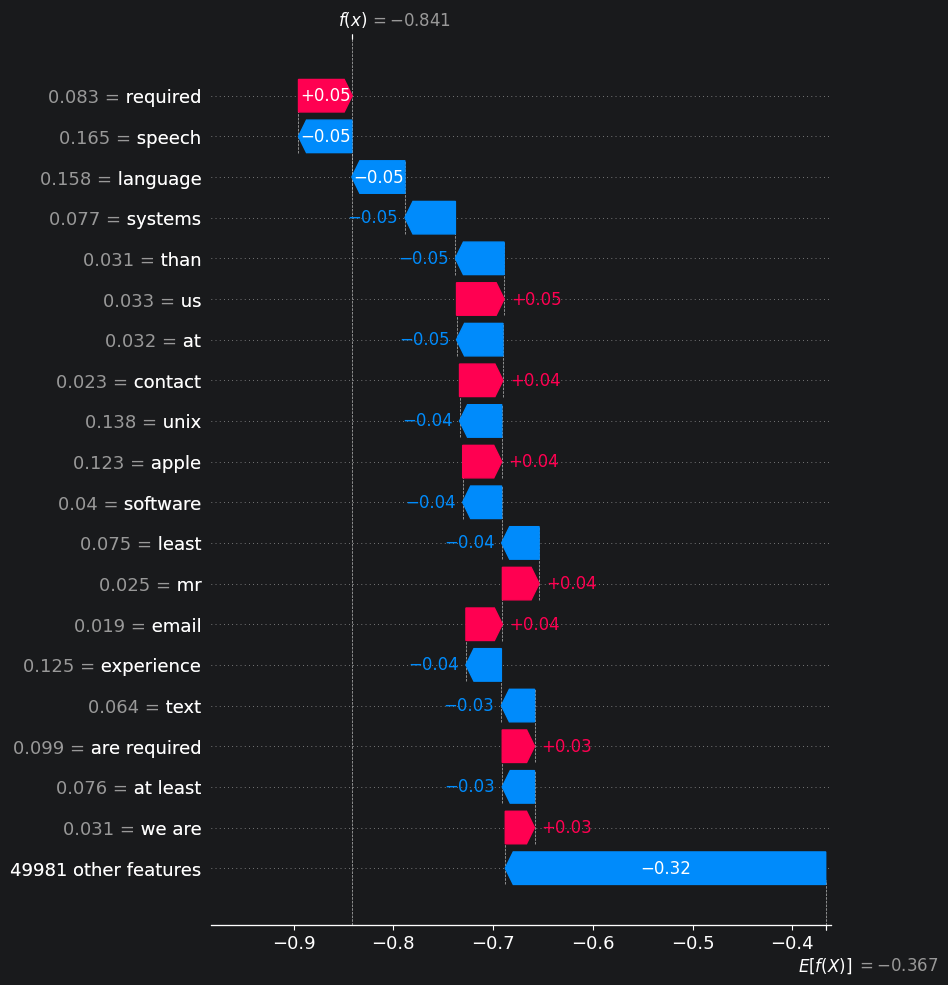

In [123]:
# 1 is the best C value overall for all datasets
ling_spam_best_params = {'classifier__C': 1}
ling_spam_model, ling_spam_test_df = train_model_for_interpretation("Ling-Spam",
                                                                    LogisticRegression(**LOGISTIC_REGRESSION_PARAMS),
                                                                    ling_spam_best_params)
explain_model(ling_spam_model, ling_spam_test_df)

LogisticRegression(C=1, random_state=42, solver='liblinear')


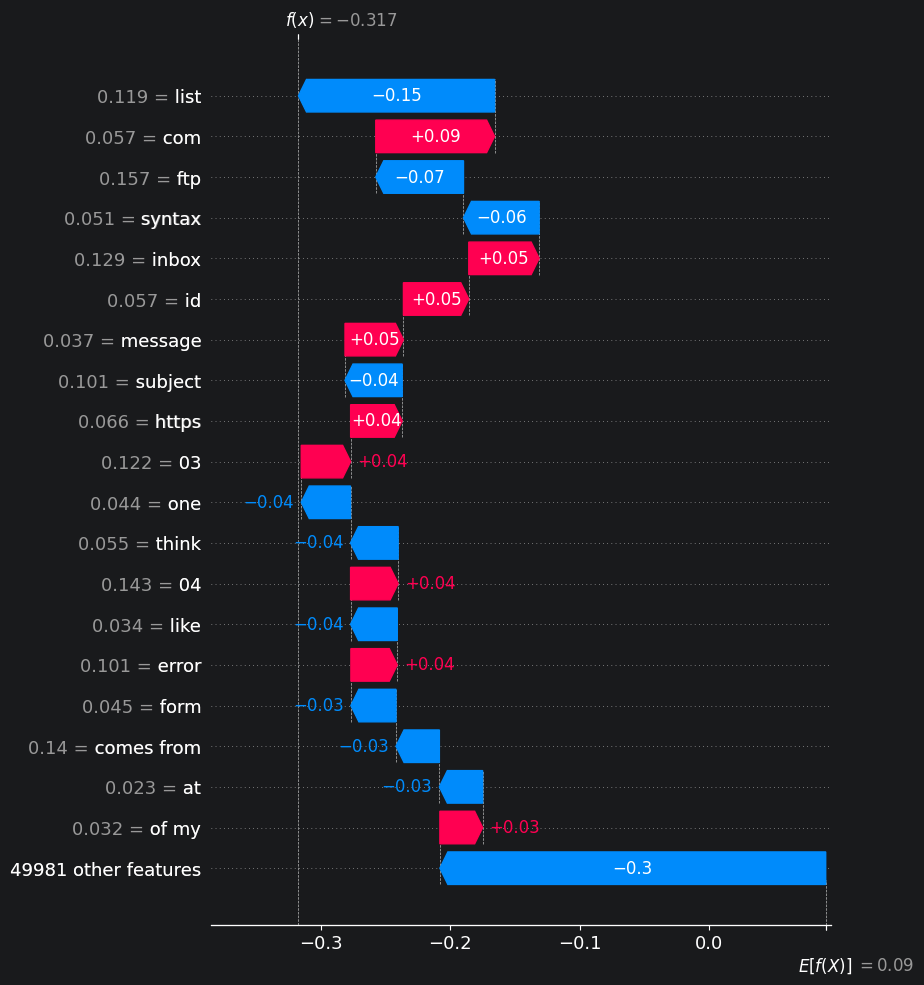

In [124]:
spam_assassin_best_params = {'classifier__C': 1}
spam_assassin_model, spam_assassin_test_df = train_model_for_interpretation("SpamAssassin", LogisticRegression(
    **LOGISTIC_REGRESSION_PARAMS), spam_assassin_best_params)
explain_model(spam_assassin_model, spam_assassin_test_df)

LogisticRegression(C=1, random_state=42, solver='liblinear')


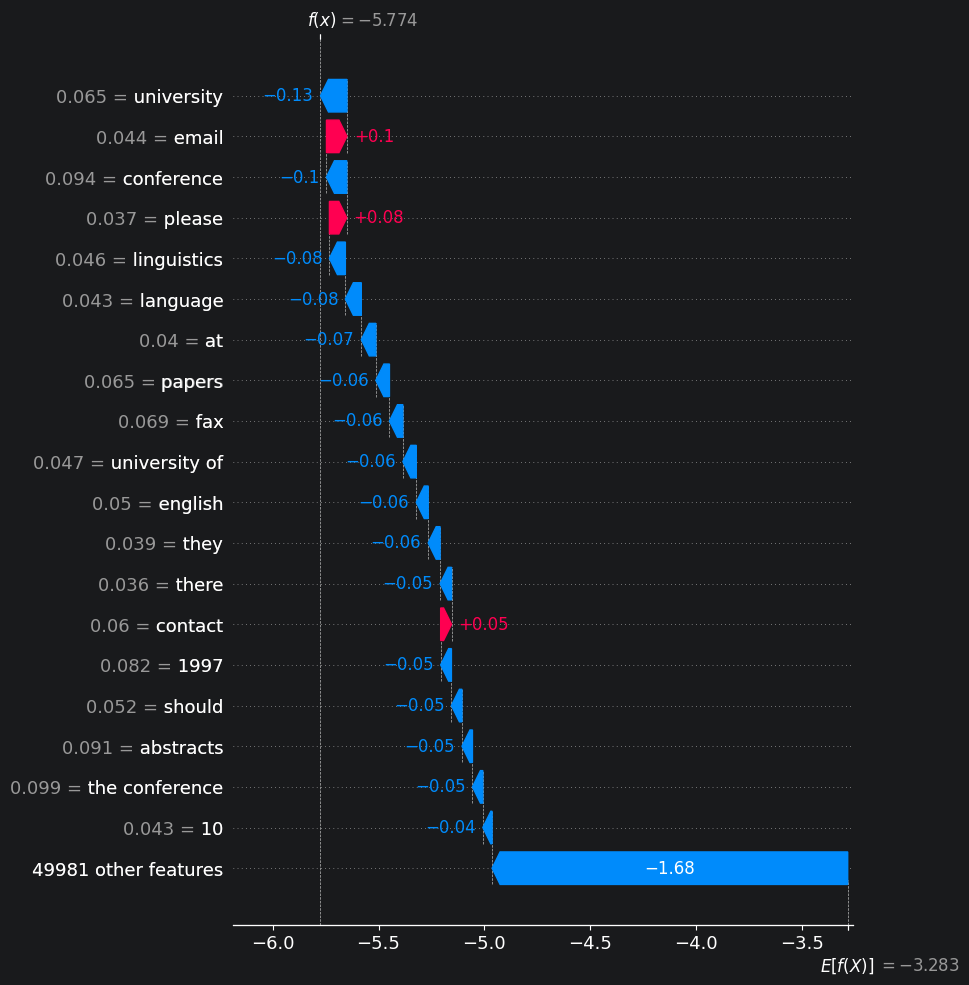

In [130]:
nigerian_fraud_best_params = {'classifier__C': 1}
nigerian_fraud_model, nigerian_fraud_test_df = train_model_for_interpretation("Nigerian_Fraud", LogisticRegression(
    **LOGISTIC_REGRESSION_PARAMS), nigerian_fraud_best_params)

explain_model(nigerian_fraud_model, nigerian_fraud_test_df)

LogisticRegression(C=1, random_state=42, solver='liblinear')


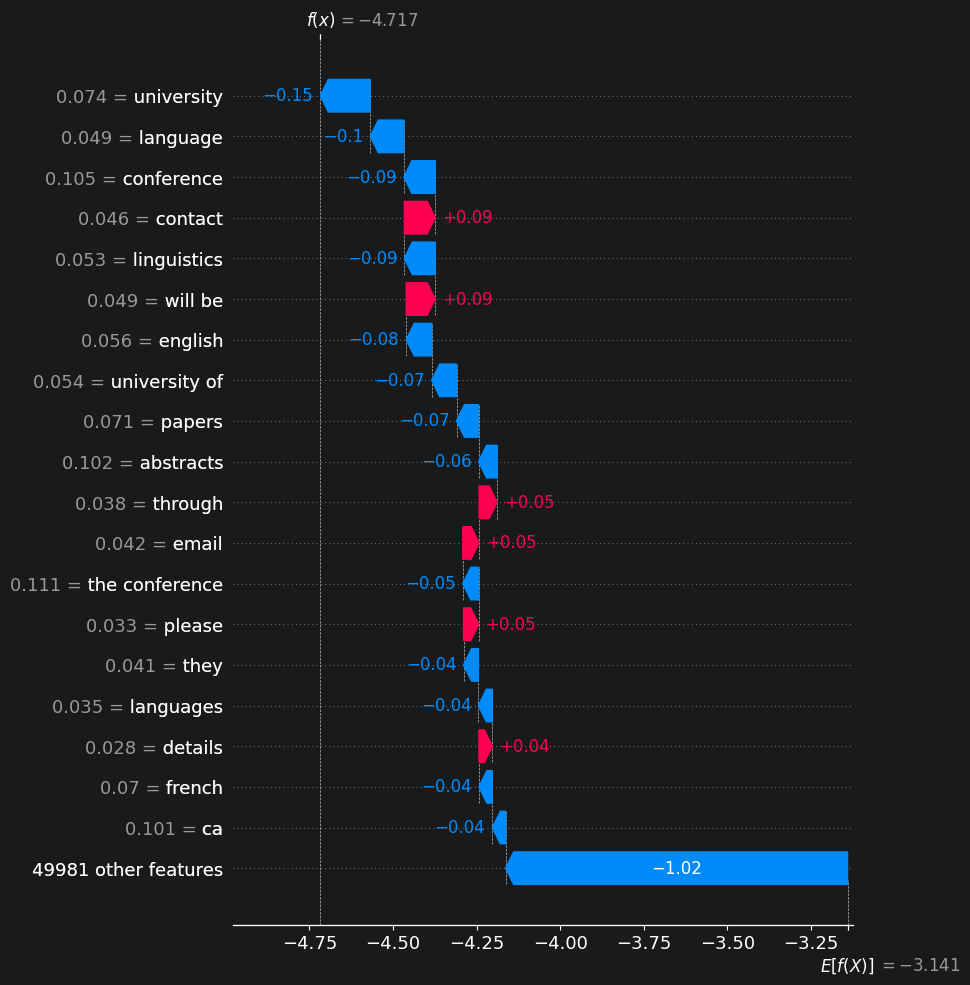

In [127]:
nazario_best_params = {'classifier__C': 1}
nazario_model, nazario_test_df = train_model_for_interpretation("Nazario",
                                                                LogisticRegression(**LOGISTIC_REGRESSION_PARAMS),
                                                                nazario_best_params)

explain_model(nazario_model, nazario_test_df)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device='cpu', early_stopping_rounds=None,
              enable_categorical=False, eval_metric='aucpr', feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.05, max_bin=128, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=5,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=500,
              n_jobs=-1, num_parallel_tree=None, ...)


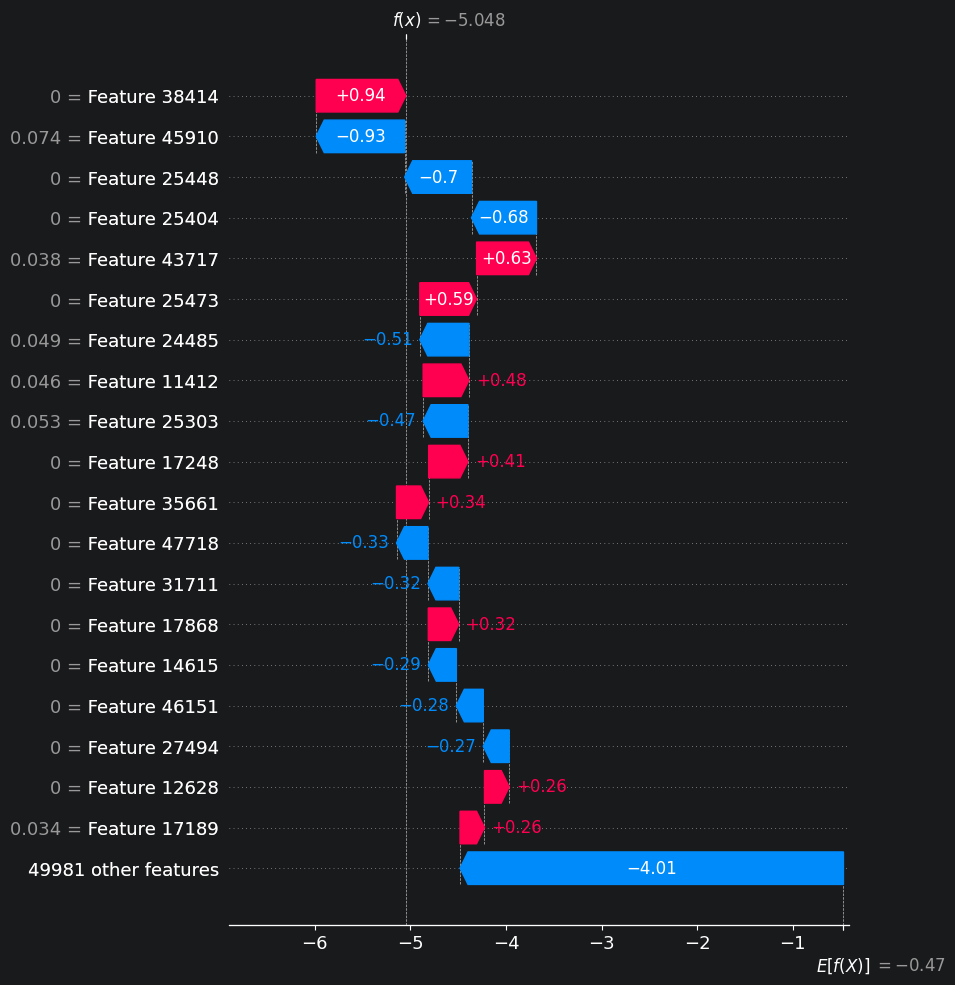

In [137]:
# One test with the best XGB model on the Nigerian Fraud dataset (l_rate = 0.05) to see the feature importance with SHAP
nazario_best_params_xgb = {'classifier__learning_rate': 0.05}
nazario_model_xgb, nazario_test_df_xgb = train_model_for_interpretation("Nazario", XGBClassifier(**XGB_PARAMS),
                                                                        nazario_best_params_xgb)

explain_model(nazario_model_xgb, nazario_test_df_xgb)

## References

[1] D. A. Jenifer and S. Janit, “Email Forensics Using Machine and Deep Learning Techniques for Cybercrime Detection,” in 2025 International Conference on Intelligent and Secure Engineering Solutions (CISES), Greater Noida Gautam Budh Nagar, India: IEEE, Aug. 2025, pp. 1248–1252. doi: 10.1109/CISES66934.2025.11265002.

[2] M. Hina, M. Ali, A. R. Javed, F. Ghabban, L. A. Khan, and Z. Jalil, “SeFACED: Semantic-Based Forensic Analysis and Classification of E-Mail Data Using Deep Learning,” IEEE Access, vol. 9, pp. 98398–98411, 2021, doi: 10.1109/ACCESS.2021.3095730.


